In [55]:
# Assignment No: 04
# Aim:
# To implement an Autoencoder for anomaly detection.
# Problem Statement:
# Use an Autoencoder to implement anomaly detection. Build the model by:
# 1. Importing required libraries
# 2. Accessing/downloading the dataset
# 3. Building the Encoder to convert inputs into latent representations
# 4. Building the Decoder to convert latent representations back to original inputs
# 5. Compiling and training the model with Optimizer, Loss, and Evaluation Metrics
# 6. Evaluating the model to determine anomalies using reconstruction error

In [1]:
# If needed, uncomment:
# %pip install -q tensorflow pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Step 1: Import Required Libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [5]:
# Step 2: Access the Dataset
# Download the dataset
datafile = tf.keras.utils.get_file(
    'ecg_data.csv',
    'http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv'
)

df = pd.read_csv(datafile, header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [7]:
# Preprocess the Dataset
raw_data = df.values

# The last column contains the labels (1 for normal, 0 for abnormal)
labels = raw_data[:, -1]
data = raw_data[:, 0:-1]

# Split into train and test sets
train_data, test_data, train_labels, test_labels = train_test_split(
    data, labels, test_size=0.2, random_state=21
)

# Normalize data to [0, 1]
min_val = tf.reduce_min(train_data)
max_val = tf.reduce_max(train_data)

train_data = (train_data - min_val) / (max_val - min_val)
test_data = (test_data - min_val) / (max_val - min_val)

train_data = tf.cast(train_data, tf.float32)
test_data = tf.cast(test_data, tf.float32)

# Separate normal (1) and anomalous (0) data points
normal_train_data = train_data[train_labels == 1]
normal_test_data = test_data[test_labels == 1]

anomalous_train_data = train_data[train_labels == 0]
anomalous_test_data = test_data[test_labels == 0]

print(f"Normal train samples: {len(normal_train_data)}")
print(f"Anomalous train samples: {len(anomalous_train_data)}")

Normal train samples: 2359
Anomalous train samples: 1639


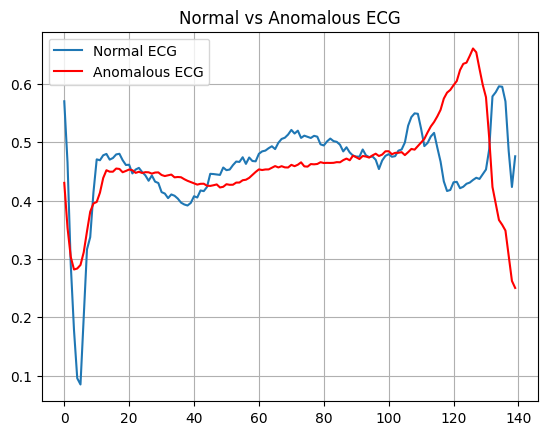

In [9]:
# Visualize Normal vs. Anomalous ECG Signals
plt.grid()
plt.plot(np.arange(140), normal_train_data[0], label="Normal ECG")
plt.plot(np.arange(140), anomalous_train_data[0], label="Anomalous ECG", color='red')
plt.title("Normal vs Anomalous ECG")
plt.legend()
plt.show()

In [11]:
# Step 3 & 4: Build Encoder and Decoder Architecture
class AnomalyDetector(Model):
  def __init__(self):
    super(AnomalyDetector, self).__init__()
    # Encoder network
    self.encoder = tf.keras.Sequential([
      layers.Dense(32, activation="relu"),
      layers.Dense(16, activation="relu"),
      layers.Dense(8, activation="relu") # Latent representation (bottleneck)
    ])

    # Decoder network
    self.decoder = tf.keras.Sequential([
      layers.Dense(16, activation="relu"),
      layers.Dense(32, activation="relu"),
      layers.Dense(140, activation="sigmoid") # Reconstructed representation
    ])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

autoencoder = AnomalyDetector()

In [13]:
# Step 5: Compile and Train the Model
autoencoder.compile(optimizer='adam', loss='mae')

history = autoencoder.fit(
    normal_train_data,
    normal_train_data,
    epochs=20,
    batch_size=512,
    validation_data=(test_data, test_data),
    shuffle=True
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 214ms/step - loss: 0.0585 - val_loss: 0.0530
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - loss: 0.0557 - val_loss: 0.0512
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.0528 - val_loss: 0.0491
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - loss: 0.0487 - val_loss: 0.0475
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - loss: 0.0443 - val_loss: 0.0450
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0401 - val_loss: 0.0427
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 0.0363 - val_loss: 0.0414
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0331 - val_loss: 0.0397
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.0305 - val_loss: 0.0389
Epoch 10/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0287 - val_loss: 0.0382
Epoch 11/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - loss: 0.0272 - val_loss: 0.0371
Epoch 12/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 0.0260 - val_loss: 0.0365


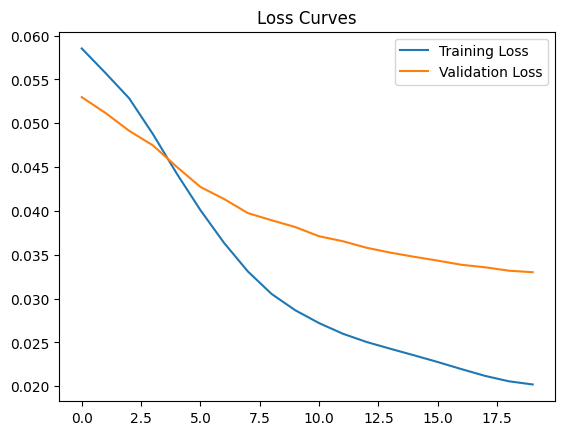

In [15]:
# Plot Training and Validation Loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss Curves")
plt.legend()
plt.show()

In [17]:
# Step 6: Evaluate Model and Detect Anomalies
# Reconstruction error on normal training data
reconstructions = autoencoder.predict(normal_train_data)
train_loss = tf.keras.losses.mae(reconstructions, normal_train_data)

# Determine threshold (mean + 1 standard deviation of normal training loss)
threshold = np.mean(train_loss) + np.std(train_loss)
print("Reconstruction error threshold:", threshold)

# Evaluate anomaly detection performance on test set
def predict(model, data, threshold):
  reconstructions = model(data)
  loss = tf.keras.losses.mae(reconstructions, data)
  return tf.less(loss, threshold)

preds = predict(autoencoder, test_data, threshold)

print(f"Accuracy = {accuracy_score(test_labels, preds):.4f}")
print(f"Precision = {precision_score(test_labels, preds):.4f}")
print(f"Recall = {recall_score(test_labels, preds):.4f}")

74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step   
Reconstruction error threshold: 0.03210389
Accuracy = 0.9450
Precision = 0.9922
Recall = 0.9089
